# 04. Variant 1: LS-SVM

## Ý tưởng cần code: đổi hinge loss thành squared loss và ràng buộc bất đẳng thức thành đẳng thức. Khi đó toàn bộ điều kiện KKT thành một hệ phương trình tuyến tính (Chương 2.1.3):

$$
\begin{bmatrix}
0 & y^\top \\
y & \Omega + D^{-1}
\end{bmatrix}
\begin{bmatrix}
b \\
\alpha
\end{bmatrix}
=
\begin{bmatrix}
0 \\
\mathbf{1}
\end{bmatrix}
$$

$$
\Omega_{ij} = y_i y_j K(x_i, x_j),
\qquad
D = \operatorname{diag}(C c_i)
$$

## import tools.py và models.py

In [6]:
import sys, json
sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.tools import load_features, tune_walk_forward, evaluate_on_test, summarize, train_test
from src.models import LSSVM

data = load_features()

## Lưới tham số và chọn tham số

In [7]:
GRID = [
    {"kernel": ["linear"], "C": [0.01, 0.1, 1, 10]},
    {"kernel": ["rbf"], "C": [0.1, 1, 10], "gamma": [0.01, 0.05, 0.2]},
]
best, rows = tune_walk_forward(LSSVM, GRID, data.loc[:"2022"])
json.dump({"best": best, "rows": rows}, open("../reports/tables/tuning_LS-SVM.json", "w"), indent=1)
print("Tham số tốt nhất:", best)
pd.DataFrame([{**r["params"], "BalAcc_val": r["BalAcc"], "std": r["std"]} for r in rows]) \
  .sort_values("BalAcc_val", ascending=False).head(8)

Tham số tốt nhất: {'kernel': 'rbf', 'C': 0.1, 'gamma': 0.01}


,kernel,C,BalAcc_val,std,gamma
4,rbf,0.10,0.511004,0.030507,0.01
0,linear,0.01,0.508690,0.029327,NaN
7,rbf,1.00,0.507686,0.014542,0.01
1,linear,0.10,0.507273,0.018766,NaN
2,linear,1.00,0.505412,0.014072,NaN
3,linear,10.00,0.502911,0.011103,NaN
5,rbf,0.10,0.500115,0.012728,0.05
11,rbf,10.00,0.495776,0.043533,0.05


## Đánh giá trên test

In [8]:
res = evaluate_on_test("LS-SVM", LSSVM, best, data)
res.to_csv("../reports/tables/test_LS-SVM.csv", index=False)
summarize(res, ["Accuracy", "BalAcc", "F1", "AUC", "MCC", "UpRate", "time_s", "nonzero"])

,Accuracy,BalAcc,F1,AUC,MCC,UpRate,time_s,nonzero
model,,,,,,,,
LS-SVM,0.5141,0.5021,0.5794,0.5119,0.0041,0.5770,0.1068,1.0000


## Kiểm chứng αᵢ = C·cᵢ·eᵢ

Tỷ lệ alpha khác 0: 1.0
Ràng buộc y_i f(x_i) = 1 - e_i đúng không: True


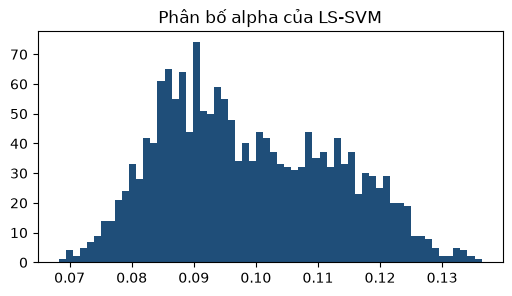

In [9]:
X_train, y_train, *_ = train_test(data)
m = LSSVM(**best).fit(X_train, y_train)
e = m.alpha_ / (best["C"] * m.cw_)                     # từ KKT: alpha_i = C c_i e_i
print("Tỷ lệ alpha khác 0:", m.nonzero_ratio_)
print("Ràng buộc y_i f(x_i) = 1 - e_i đúng không:",
      np.allclose(y_train * m.decision_function(X_train), 1 - e, atol=1e-6))
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(m.alpha_, bins=60, color="#1f4e79"); ax.set_title("Phân bố alpha của LS-SVM")
fig.savefig("../reports/figures/fig_lssvm_alpha.png", dpi=150, bbox_inches="tight")